# Inspection of The Results

After all the experiments were ran, it is time to inspect and analyze the outcome. There will be the following parts to that:
1. General inspection of constraint properties, excluding coverage and regularity. The subjects of the inspection will be the distributions of the constraints by 1) the type of linguistic information they employ; 2) their target item.
2. General inspection of the coverage and regularity measures. At this step, the obtained values will be inspected, which includes the analysis of their distribution and correlation.
3. Inspection of item against type regularity values. This inspection gives an idea about the presence of negative outliers within covered items of the constraints.
4. Inspection of the extent to which the claims about the constraints made in the literature are supported by the data. That includes comparison of the quantifiers specified in the constraint definitions ("regularly", "mostly" etc.) and the obtained item regularity values. We concentrate on the item variant since we want a more balanced estimation not affected by productive outliers.
5. Inspection of the extent to which our suggestions to the definitions of not fully supported constraints are supported by the data.

In [1]:
# project-level pwd
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private


In [2]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, chi2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.markers import MarkerStyle
from collections import Counter, defaultdict
from itertools import product
import yaml
from typing import List

## 1. General Inspection of Constraint Properties

Our goal for this step of inspection is to retrieve the following:
1. The distribution of the constraints by the type of linguistic information they employ.
2. The distribution of the constraints by their target items.

Both properties are retrievable directly from the [master constraints file](../constraints/constraints_all_revised.yaml) so we load and access it here.

In [3]:
constr_path = "constraints/constraints_all_revised.yaml"
# constr_corr_path = "constraints/constraint_corrections.yaml"

appl_stat_dir = "out/constraints/applicability_statistics"
constr_stat_dir = "out/constraints/constraint_statistics/"

# os.makedirs(appl_stat_dir, exist_ok=True)
os.makedirs(constr_stat_dir, exist_ok=True)

In [4]:
save_tsv = lambda df, path: df.to_csv(
    path,
    sep="\t",
    header=True,
    index=True
)

save_cstat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(constr_stat_dir, f"{name}.tsv")
)

save_astat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(appl_stat_dir, f"{name}.tsv")
)

In [5]:
# load constraints and dataset specs
with open(constr_path, encoding="utf-8") as f:
    yamls = list(yaml.safe_load_all(f))
    constraints: dict = yamls[-1]["constraints"]
    data_specs: dict = yamls[-2]["datasets"]

### 1.1. Distribution of Constraints by Linguistic Information Type

Beside the linguistic info type, we will also distinguish between the application type (P2l/L2P).

In [6]:
ling_type_data = {
    "p2l": defaultdict(int),
    "l2p": defaultdict(int)
}

for c_id, constraint in constraints.items():
    if c_id == "def-0": # disregard the default constraint
        continue
    ling_type = sorted(constraint["ling_info_type"])    # sort for multiple types
    ling_type_str = "+".join(ling_type)
    appl_type = c_id.split(":")[0]
    ling_type_data[appl_type][ling_type_str] += 1

ling_types = pd.DataFrame(
    data=ling_type_data
).fillna(0).astype(int).sort_index()

save_cstat_tsv(ling_types, "ling_types")
ling_types

,p2l,l2p
derivational,9,2
derivational+morphological,1,1
derivational+morphological+phonological,1,0
derivational+phonological,0,3
derivational+semantic,2,0
lexical,1,4
lexical+morphological,0,1
lexical+morphological+phonological+semantic,0,1
lexical+semantic,1,0
morphological,6,6


In [7]:
ling_types["p2l"].sum().item(), ling_types["l2p"].sum().item()

(41, 22)

In [8]:
domains = ["morphological", "derivational", "phonological", "semantic", "lexical"]

domain_df = pd.Series(
	index=domains,
	data=
	{
		t: ling_types[
			ling_types.index.str.contains(t)
		].sum().sum().item()
		for t in domains
	}
)

save_cstat_tsv(domain_df, "involved_domains")
domain_df

morphological    33
derivational     19
phonological     18
semantic         19
lexical           8
dtype: int64

### 1.2. Distribution of Constraints by Target Item

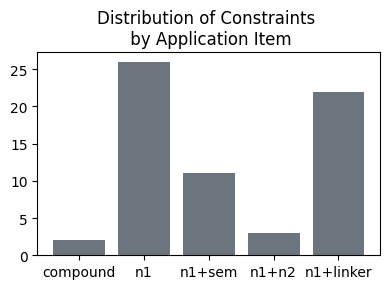

In [9]:
appl_items = [c["appl_item"] for c in constraints.values()]
counts = Counter(appl_items)
keys, values = counts.keys(), counts.values()

plt.figure(figsize=(4, 3))

bars = plt.bar(keys, values, color="#6c757d")

plt.title("Distribution of Constraints \n by Application Item")

plt.tight_layout()
plt.savefig(
    os.path.join(constr_stat_dir, "appl_item_distr.png"),
    dpi="figure"
)
plt.show()

Additionally, we want to know which number of possible items each type has. For that, we need to access GeCoDB_v06.

In [10]:
appl_item_counts_data = defaultdict(dict)

# TODO: optimize
for c_id, dname in product(constraints, data_specs):
    constr = constraints[c_id]
    if dname not in constr["datasets_n_appl_items"]:
        continue
    appl_item_counts_data[constr["appl_item"]][dname] = constr["datasets_n_appl_items"][dname]

appl_item_counts = pd.DataFrame(appl_item_counts_data)

save_cstat_tsv(appl_item_counts, "appl_item_counts")
appl_item_counts

,compound,n1,n1+sem,n1+linker
gecodb_v06,282767.0,3614.0,NaN,4870
gecodb_v07,277361.0,3594.0,NaN,4788
sp18_pl_constr,NaN,NaN,78.0,88


## 2. General Inspection of The Coverage and Regularity Measures

Here, we load the general applicability statistics table and retrieve three things:
1. Scatter plots of coverage against regularity in two variants each (item, type).
    * A shared plot.
    * P2L vs L2P.
2. Central tendency measures of the distributions (shared, P2L, L2P).
3. Qualitative analysis of the values clusters.

### 2.1. Draw Scatter Plot

In [11]:
stats = pd.read_csv(
    os.path.join(appl_stat_dir, "appl_statistics_summary.tsv"),
    sep="\t",
    index_col=(0, 1),
    header=0
).dropna()  # remove non-implemented constraints

stats

appl_item  n_appl_items  \
constr_id                 dataset                                   
def-0                     gecodb_v06       compound      282767.0   
                          gecodb_v07       compound      277361.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06             n1        3614.0   
                          gecodb_v07             n1        3594.0   
p2l:decl_cl:pl:#s-0       gecodb_v06             n1        3614.0   
...                                             ...           ...   
l2p:es|mono_syl           gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4788.0   
l2p:0_uml                 gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4788.0   
l2p:pl_marker|def-pl      sp18_pl_constr  n1+linker          88.0   

                                                quantifier  cvg_item  \
constr_id                 dataset                                      
def-0                     gecodb_v06              majority     1.000   
                          gecodb_v07              majority     1.000   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06      almost regularly     0.067   
                          gecodb_v07      almost regularly     0.067   
p2l:decl_cl:pl:#s-0       gecodb_v06            almost all     0.035   
...                                                    ...       ...   
l2p:es|mono_syl           gecodb_v06                   all     0.012   
                          gecodb_v07                   all     0.011   
l2p:0_uml                 gecodb_v06                   all     0.003   
                          gecodb_v07                   all     0.003   
l2p:pl_marker|def-pl      sp18_pl_constr              tend     0.455   

                                          cvg_type  reg_item  reg_type  \
constr_id                 dataset                                        
def-0                     gecodb_v06         1.000     0.578     0.578   
                          gecodb_v07         1.000     0.577     0.577   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.066     0.954     0.936   
                          gecodb_v07         0.065     0.955     0.937   
p2l:decl_cl:pl:#s-0       gecodb_v06         0.033     0.970     0.957   
...                                            ...       ...       ...   
l2p:es|mono_syl           gecodb_v06         0.011     0.983     0.940   
                          gecodb_v07         0.011     0.964     0.939   
l2p:0_uml                 gecodb_v06         0.000     1.000     1.000   
                          gecodb_v07         0.000     1.000     1.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.465     0.146     0.153   

                                                support_level  
constr_id                 dataset                              
def-0                     gecodb_v06                supported  
                          gecodb_v07                supported  
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06                supported  
                          gecodb_v07                supported  
p2l:decl_cl:pl:#s-0       gecodb_v06                supported  
...                                                       ...  
l2p:es|mono_syl           gecodb_v06                supported  
                          gecodb_v07      partially supported  
l2p:0_uml                 gecodb_v06                supported  
                          gecodb_v07                supported  
l2p:pl_marker|def-pl      sp18_pl_constr        not supported  

[87 rows x 8 columns]

In [12]:
stat_ids = np.unique([ind[0] for ind in stats.index])
len(stat_ids)

48

In [13]:
np.char.startswith(stat_ids, "p2l:").sum().item(), np.char.startswith(stat_ids, "l2p:").sum().item()

(31, 16)

In [14]:
stats = stats.swaplevel(0, 1)

Now draw the plots. We start with the shared plot.

In [15]:
dot_kw = {
    "facecolors": "none",   # hollow inside
    "edgecolors": "black",  # outline
    "s": 100                 # marker size
}

line_kw = {
    "color": "black",
    "linewidth": 0.5,
    "linestyle": "--",
    "alpha": 0.6
}

line_label_kw = {
    "fontsize": 7,
    "alpha": 0.8,
    "clip_on": False
}

# https://matplotlib.org/stable/api/markers_api.html#module-matplotlib.markers
markers = {
    # add with new datasets
    "gecodb_v06": "o",
    "gecodb_v07": "v",
    "sp18_pl_constr": "p",
    # "*",
    # "s"
}

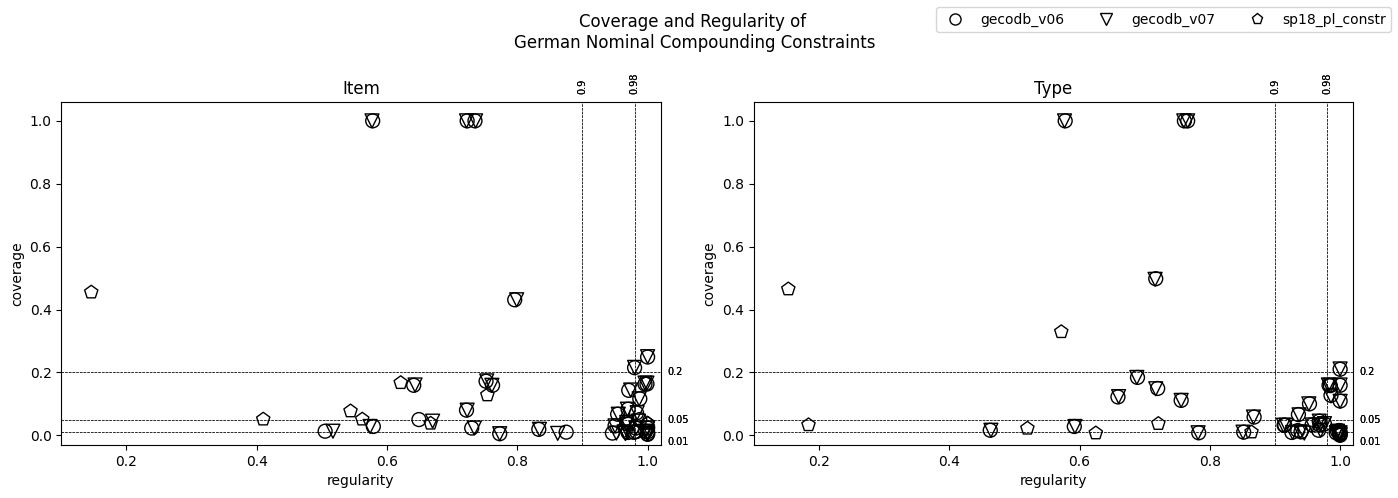

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

legend = []
for dname in data_specs:

    stats_dname = stats.loc[dname]
    marker = markers[dname]

    # item cvg/reg values
    axes[0].scatter(
        stats_dname["reg_item"],
        stats_dname["cvg_item"],
        **dot_kw,
        marker=marker
    )
    axes[0].set_xlabel("regularity")
    axes[0].set_ylabel("coverage")
    axes[0].set_title("Item")


    # type cvg/reg values
    axes[1].scatter(
        stats_dname["reg_type"],
        stats_dname["cvg_type"],
        **dot_kw,
        marker=marker
    )
    axes[1].set_xlabel("regularity")
    axes[1].set_ylabel("coverage")
    axes[1].set_title("Type")

    for ax in axes:

        ax.set_xlim(0.1, 1.02)
        ax.set_ylim(-0.03, 1.06)

        # horizontal lines for coverage
        for y in [0.01, 0.05, 0.2]:
            ax.axhline(y=y, **line_kw)
            ax.text(
                1.03, y - (0.03 * (y == 0.01)), y,
                va="center", ha="left", **line_label_kw
            )

        # vertical lines for regularity
        for x in [0.9, 0.98]:
            ax.axvline(x=x, **line_kw)
            ax.text(
                x, 1.085, x,
                va="bottom", ha="center",
                rotation=90, **line_label_kw
            )

    legend_handle = mlines.Line2D(
        [], [], color="black", marker=marker, linestyle="None",
        markersize=8, markerfacecolor="none", label=dname
    )
    legend.append(legend_handle)

fig.suptitle(
    "Coverage and Regularity of \n"
    "German Nominal Compounding Constraints"
)
fig.legend(handles=legend, loc="upper right", ncol=len(legend))

plt.tight_layout()
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg.png"),
    dpi="figure"
)
plt.show()

In [17]:
r = lambda x, y: x.corr(y, method="pearson")

mw_gecodb_v06_vs_gecodb_v07_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    mw = mannwhitneyu(stats.loc["gecodb_v06", param_str], stats.loc["gecodb_v07", param_str])
    mw_gecodb_v06_vs_gecodb_v07_data[param] = {
        "U": mw.statistic,
        "p": mw.pvalue,
        "r": r(stats.loc["gecodb_v06", param_str], (stats.loc["gecodb_v07", param_str]))
    }

mw_gecodb_v06_vs_gecodb_v07 = pd.DataFrame(mw_gecodb_v06_vs_gecodb_v07_data).round(3)

save_astat_tsv(mw_gecodb_v06_vs_gecodb_v07, "mw_gecodb_v06_vs_gecodb_v07")
mw_gecodb_v06_vs_gecodb_v07

reg              cvg         
      item     type    item     type
U  784.500  762.000  768.50  783.000
p    0.814    0.992    0.94    0.826
r    0.999    1.000    1.00    1.000

=> we can use either

In [18]:
set(stats.loc["gecodb_v07"].index) & set(stats.loc["sp18_pl_constr"].index)

set()

In [19]:
stats_flat = stats.loc[["gecodb_v07", "sp18_pl_constr"]]    \
    .reset_index(level=0, drop=False)
stats_flat

,dataset,appl_item,n_appl_items,quantifier,cvg_item,cvg_type,reg_item,reg_type,support_level
constr_id,,,,,,,,,
def-0,gecodb_v07,compound,277361.0,majority,1.000,1.000,0.577,0.577,supported
p2l:decl_cl:pl:#0-0|def-0,gecodb_v07,n1,3594.0,almost regularly,0.067,0.065,0.955,0.937,supported
p2l:decl_cl:pl:#s-0,gecodb_v07,n1,3594.0,almost all,0.035,0.033,0.968,0.957,supported
p2l:decl_cl:pl:#e-0|def-0,gecodb_v07,n1,3594.0,mostly,0.159,0.184,0.761,0.688,supported+
p2l:decl_cl:pl:#er-0/er|def-0/er,gecodb_v07,n1,3594.0,mostly,0.019,0.058,0.834,0.867,supported+
p2l:decl_cl:pl:#e_uml-0|def-0,gecodb_v07,n1,3594.0,mostly,0.080,0.111,0.723,0.756,supported+
p2l:decl_cl:pl:#0_uml-0|def-0,gecodb_v07,n1,3594.0,almost always,0.007,0.016,0.952,0.970,supported
p2l:decl_cl:mixed-0/s/en|def-0/s/en,gecodb_v07,n1,3594.0,regularly,0.013,0.013,0.996,0.996,supported
p2l:drv:sfx:0_pl_sfx-0,gecodb_v07,n1,3594.0,regularly,0.072,0.045,0.984,0.968,supported


In [20]:
stats_flat_p2l = stats_flat[stats_flat.index.str.startswith("p2l:")]
stats_flat_l2p = stats_flat[stats_flat.index.str.startswith("l2p:")]

In [21]:
def get_cvg_reg_clusters(stats: pd.DataFrame) -> dict:
    return {
        ("cvg_comb", ">= 0.2"): stats[
            (stats["cvg_item"] >= 0.2) & (stats["cvg_type"] >= 0.2)
        ].shape[0],
        ("cvg_comb", "< 0.2"): stats[
            (stats["cvg_item"] < 0.2) & (stats["cvg_type"] < 0.2)
        ].shape[0],
        ("cvg_comb", "< 0.05"): stats[
            (stats["cvg_item"] < 0.05) & (stats["cvg_type"] < 0.05)
        ].shape[0],
        ("reg_comb", "<= 0.9"): stats[
            (stats["reg_item"] <= 0.9) & (stats["reg_type"] <= 0.9)
        ].shape[0],
        ("reg_comb", "> 0.9"): stats[
            (stats["reg_item"] > 0.9) & (stats["reg_type"] > 0.9)
        ].shape[0],
        ("reg_comb", "> 0.98"): stats[
            (
                (stats["reg_item"] > 0.98) |
                (
                    (stats["cvg_item"] <= 0.01)
                    & (stats["reg_item"] > 0.97)
                )
            ) & 
            (stats["reg_type"] > 0.98)
        ].shape[0]
    }

cvg_reg_clusters = pd.DataFrame(
    {
        "all": get_cvg_reg_clusters(stats_flat),
        "P2L": get_cvg_reg_clusters(stats_flat_p2l),
        "L2P": get_cvg_reg_clusters(stats_flat_l2p)
    }
)

save_astat_tsv(cvg_reg_clusters, "cvg_reg_clusters")
cvg_reg_clusters

all  P2L  L2P
cvg_comb >= 0.2    6    4    1
         < 0.2    40   25   15
         < 0.05   24   13   11
reg_comb <= 0.9   19   16    2
         > 0.9    25   13   12
         > 0.98   12    5    7

In [22]:
item_type_desc_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    item_type_desc_data[param] = stats_flat[param_str] \
        .describe(percentiles=[0.5, 0.9])

item_type_desc = pd.concat(item_type_desc_data, axis=1).T.round(3)
save_astat_tsv(item_type_desc, "item_type_desc")
item_type_desc

count   mean    std    min    50%    90%  max
reg item   48.0  0.831  0.197  0.146  0.954  1.000  1.0
    type   48.0  0.836  0.209  0.153  0.938  1.000  1.0
cvg item   48.0  0.140  0.245  0.003  0.045  0.304  1.0
    type   48.0  0.135  0.251  0.000  0.033  0.370  1.0

In [23]:
corr_cvg_reg = pd.DataFrame({
    "r": {
        v: stats_flat[f"reg_{v}"].corr(stats_flat[f"cvg_{v}"], method="pearson")
        for v in ["item", "type"]
    }
}).T.round(3)

save_astat_tsv(corr_cvg_reg, "corr_cvg_reg")
corr_cvg_reg

,item,type
r,-0.32,-0.321


In [24]:
mw_item_type = pd.DataFrame({
   param: {
        "U": (mw := mannwhitneyu(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])).statistic,
        "p": mw.pvalue,
        "r": r(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"]),
        "mae": mean_absolute_error(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])
    }
    for param in ["cvg", "reg"]
}).round(3)

save_astat_tsv(mw_item_type, "mw_item_type")
mw_item_type

,cvg,reg
U,1283.000,1116.500
p,0.339,0.797
r,0.990,0.928
mae,0.021,0.043


In [25]:
cvg_reg_desc_data = {}
for param in ["cvg", "reg"]:
    for sname, sample in [
        ("all", stats_flat),
        ("P2L", stats_flat_p2l),
        ("L2P", stats_flat_l2p)
    ]:
        cvg_reg_desc_data[(param, sname)] = sample[f"{param}_item"] \
            .describe(percentiles=[0.5, 0.9])

cvg_reg_desc = pd.concat(cvg_reg_desc_data, axis=1).T.round(3)
save_astat_tsv(cvg_reg_desc, "cvg_reg_desc")
cvg_reg_desc

count   mean    std    min    50%    90%    max
cvg all   48.0  0.140  0.245  0.003  0.045  0.304  1.000
    P2L   31.0  0.145  0.246  0.005  0.051  0.250  1.000
    L2P   16.0  0.078  0.117  0.003  0.023  0.166  0.455
reg all   48.0  0.831  0.197  0.146  0.954  1.000  1.000
    P2L   31.0  0.809  0.178  0.410  0.799  1.000  1.000
    L2P   16.0  0.890  0.222  0.146  0.978  1.000  1.000

In [26]:
mw_p2l_l2p_data = {}
for sign, a in [("=", "two-sided"), (">", "greater"), ("<", "less")]:
    res = pd.DataFrame({
        param: {
            f"U": (mw := mannwhitneyu(stats_flat_p2l[f"{param}_item"], stats_flat_l2p[f"{param}_type"], alternative=a)).statistic,
            f"p": mw.pvalue
        }
        for param in ["cvg", "reg"]
    })
    mw_p2l_l2p_data[f"P2L{sign}L2P"] = res
mw_p2l_l2p = pd.concat(mw_p2l_l2p_data, names=["alternative"]).round(3)

save_astat_tsv(mw_p2l_l2p, "mw_p2l_l2p")
mw_p2l_l2p

cvg      reg
alternative                    
P2L=L2P     U  339.500  137.000
            p    0.041    0.013
P2L>L2P     U  339.500  137.000
            p    0.020    0.994
P2L<L2P     U  339.500  137.000
            p    0.981    0.006

In [27]:
# https://matplotlib.org/stable/gallery/color/named_colors.html
colors = {
    "morphological": "red",
    "derivational": "green",
    "phonological": "blue",
    "semantic": "gold",
    "lexical": "blueviolet"
}
matplotlib.rcParams["hatch.linewidth"] = 2.0

def get_dots(ling_types: List[str], marker: str) -> dict:
    ling_types = sorted(ling_types)
    match len(ling_types):
        case 1:
            dots = [{
                "facecolors": colors[ling_types[0]],
                
                "marker": marker
            }]
        case 2:
            # two halves
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                }
            ]
        case 3:
            # two halves + hatch
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                },
                {
                    "facecolors": "none",
                    "edgecolors": colors[ling_types[2]],
                    "hatch": "////",
                    "marker": marker
                }
            ]
        case _:
            raise NotImplemented
    return dots    

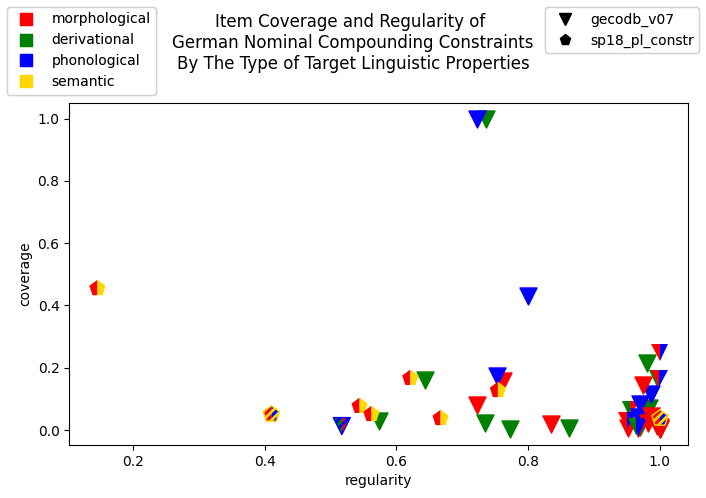

In [33]:
fig, axis = plt.subplots(1, 1, figsize=(7, 5))

for c_id, row in stats_flat.iterrows():

    if c_id == "def-0":
        continue

    marker = markers[row["dataset"]]
    dots = get_dots(constraints[c_id]["ling_info_type"], marker)
    for dot in dots:
        axis.scatter(
            row["reg_item"],
            row["cvg_item"],
            s=150,
            **dot
        )

axis.set_xlabel("regularity")
axis.set_ylabel("coverage")

legend_dataset = [
    mlines.Line2D(
        [], [], color="black", marker=markers[dname], linestyle="None",
        markersize=8, markerfacecolor="black", label=dname
    )
    for dname in stats_flat["dataset"].unique()
]
legend_colors = [
    mlines.Line2D(
        [], [], color=color, marker="s", linestyle="None",
        markersize=8, markerfacecolor=color, label=ling_type
    )
    for ling_type, color in colors.items()
    if ling_type in stats_flat
]

fig.suptitle(
    "Item Coverage and Regularity of \n"
    "German Nominal Compounding Constraints\n"
    "By The Type of Target Linguistic Properties"
)
legc = fig.legend(handles=legend_colors, loc="upper left")
legd = fig.legend(handles=legend_dataset, loc="upper right")
axis.add_artist(legc)
axis.add_artist(legd)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg_vs_ling_type.png"),
    dpi="figure"
)
plt.show()

In [29]:
ling_type_mtrx = stats_flat.apply(
    lambda row: {
        ling_type: True
        for ling_type in constraints[row.name]["ling_info_type"]
    },
    axis=1,
    result_type="expand"
)
ling_type_mtrx.fillna(False, inplace=True)
# too few representatives
ling_type_mtrx.drop(columns=["default", "lexical"], inplace=True)

In [30]:
stats_flat = pd.concat((stats_flat, ling_type_mtrx), axis=1)
stats_flat.drop("def-0", inplace=True)
stats_flat.drop(
    stats_flat[stats_flat.apply(
        lambda row: row[["morphological", "derivational", "phonological", "semantic"]].sum() == 0,
        axis=1
    )].index,
    inplace=True
)
stats_flat.sample(5)

,dataset,appl_item,n_appl_items,quantifier,cvg_item,cvg_type,reg_item,reg_type,support_level,morphological,derivational,phonological,semantic
constr_id,,,,,,,,,,,,,
p2l:drv:prx_deverb-s,gecodb_v07,n1,3594.0,tendency,0.160,0.123,0.643,0.660,supported,False,True,False,False
l2p:er|smpx,gecodb_v07,n1+linker,4788.0,most,0.006,0.007,0.862,0.945,supported+,False,True,False,False
p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml,sp18_pl_constr,n1+sem,78.0,irregularly,0.051,0.010,0.562,0.864,supported,True,False,False,True
p2l:decl_cl:pl:#0_uml-0|def-0,gecodb_v07,n1,3594.0,almost always,0.007,0.016,0.952,0.970,supported,True,False,False,False
p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en,sp18_pl_constr,n1+sem,78.0,more likely,0.038,0.009,1.000,1.000,supported+,True,False,True,True


In [31]:
X = stats_flat[["morphological", "derivational", "phonological", "semantic"]]
y = {
    "cvg": stats_flat["cvg_item"],
    "reg": stats_flat["reg_item"]
}

lr_cvg_reg_vs_ling_type_data = {}
for param in ["cvg", "reg"]:
    lr = LinearRegression(positive=False)
    lr.fit(X, y[param])
    lr_cvg_reg_vs_ling_type_data[param] = {
        "intercept": lr.intercept_,
        **{
            f"coef_{ling_type}": lr.coef_[i]
            for i, ling_type in enumerate(X.columns)
        }
    }

lr_cvg_reg_vs_ling_type = pd.DataFrame(lr_cvg_reg_vs_ling_type_data)
save_astat_tsv(lr_cvg_reg_vs_ling_type, "lr_cvg_reg_vs_ling_type")
lr_cvg_reg_vs_ling_type

,cvg,reg
intercept,0.254800,0.880016
coef_morphological,-0.167700,0.042145
coef_derivational,-0.110223,-0.039445
coef_phonological,-0.000033,0.019611
coef_semantic,0.028796,-0.292741


In [35]:
# the main effects and all possible combinations/interactions
ols = smf.ols("reg_item ~ morphological * derivational * phonological * semantic", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lmr_reg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               reg_item   R-squared:                       0.437
Model:                            OLS   Adj. R-squared:                  0.315
Method:                 Least Squares   F-statistic:                     3.589
Date:                Tue, 21 Jul 2026   Prob (F-statistic):            0.00355
Time:                        18:35:51   Log-Likelihood:                 23.437
No. Observations:                  46   AIC:                            -28.87
Df Residuals:                      37   BIC:                            -12.42
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                                                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

/Users/maksimshmalts/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private/.venv/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])


## 4. Inspection of The Extent to Which the Claims About the Constraints Made in The Literature Are Supported by The Data

The following steps are to be done for final inspection:
1. Manually inspect the support level of the claims in the empirical data. For each (analyzed) constraint, record the level of support. Since the definitions are mostly vague, base the decision on commonsense judgments. For the support level, we concentrate on the type variant of the measures since we focus on the linguistic side of the question (not real usage). There are 4 levels of support:
    * Supported. Full or very close correspondence between the quantifier and the empirical data. Examples: "regular" vs 0.99, "mostly" vs 0.75.
    * Partially supported. The gap is not critical yet noticeable. Examples: "regular" vs 0.93, "tends" vs 0.6, "sometimes" vs 0.9.
    * Not supported. The discrepancy between the quantifier and the empirical data is too significant to ignore. Examples: "regular" vs 0.85, "tends" vs 0.4.
    * NA: no data available (unreliable or semantic/lexical constraints).

Note: this steps is being conducted in the file with constraints definitions, see `constraints/constraints.yaml`. While it is being now made at the time of this inspection, we cannot reflect this processes here. After this step is done, we pull the results from this file and further inspect them in detail, specifically:

2. Inspect the distribution of the support levels.
3. Manually inspect the constraints that are only partially supported by the data or not supported at all.

### 4.1. Inspection of The Support Level

Done separately in `constraints/constraints.yaml`.

### 4.2. Inspection of Support Level Distribution

Now, we read the constraint definition file for inspection.

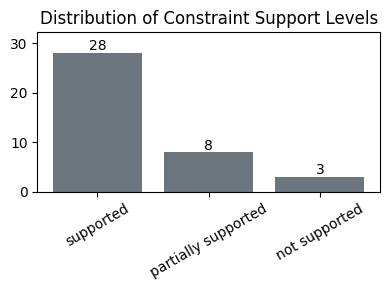

In [ ]:
sup_levels = {
    c_id: sl for c_id, c in constraints.items()
    if (sl := c["support_level"]) != "NA"
}
order = ["supported", "partially supported", "not supported"] #, "NA"]
counts = Counter(sup_levels.values())
values = [counts[k] for k in order]

plt.figure(figsize=(4, 3))

bars = plt.bar(order, values, color="#6c757d")

# add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(values) * 0.02,
        f"{int(height)}",
        ha="center"
    )

# add headroom so labels don't collide with top border
plt.ylim(0, max(values) * 1.15)
plt.title("Distribution of Constraint Support Levels")
plt.xticks(rotation=30, ha="center")
plt.tight_layout()

plt.savefig(
    os.path.join(constr_stat_dir, "sup_level_distr.png"),
    dpi=800
)
plt.show()

### 4.3. Qualitative Inspection of Partially / Not Supported Constraints

Partially supported constraints.

In [44]:
part_sup_ids = [
    c_id for c_id, sl in sup_levels.items()
    if sl == "partially supported"
]

part_sup_ids

['p2l:decl_cl:pl:#s-0',
 'p2l:phon_fin:vow$-0',
 'p2l:phon_fin:F_stem_#t$-s',
 'l2p:n',
 'l2p:en|par',
 'l2p:e|#stressed_syl',
 'l2p:er|#stressed_syl',
 'l2p:es|mono_syl']

In [45]:
# a few highly productive N1s: 'Karneval', 'Fasching', 'Interim', 'Harem'
c_id = part_sup_ids[0]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:decl_cl:pl:#s-0_item,n_bw_item
comp_gecodb,,
karneval_+s_land,karneval,194
karneval_+s_künstler,karneval,194
karneval_+s_luft,karneval,194
fasching_+s_brauchtum,fasching,129
fasching_+s_rede,fasching,129
fasching_+s_auftritt,fasching,129
interim_+s_situation,interim,64
interim_+s_wohnung,interim,64
interim_+s_kapitän,interim,64


In [46]:
# mostly loanwords ending in a long stressed [e] ('ee') or [i] ('ie'):
# 'Kaffee', 'Fee', 'Melodie', 'Chemie'
# a few examples with 'Schuh' and 'Zeg'
c_id = part_sup_ids[1]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:phon_fin:vow$-0_item,n_bw_item
comp_gecodb,,
idee_+n_bringer,idee,118
idee_+n_zentrum,idee,118
idee_+n_fetzen,idee,118
fee_+n_geschichte,fee,39
fee_+n_kreis,fee,39
fee_+n_hügel,fee,39
kalorie_+n_angabe,kalorie,36
kalorie_+n_nachschub,kalorie,36
kalorie_+n_versorgung,kalorie,36


In [47]:
# many highly productive N1 such as 'Umwelt', 'Heimat', 'Antwort'
c_id = part_sup_ids[2]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:phon_fin:F_stem_#t$-s_item,n_bw_item
comp_gecodb,,
jugend_behörde,jugend,583
jugend_gefieder,jugend,583
jugend_rente,jugend,583
umwelt_medizin,umwelt,514
umwelt_komponente,umwelt,514
...,...,...
armut_bekämpfung,armut,2
armut_zeugnis,armut,2
herkunft_staat,herkunft,2


In [48]:
# almost all word ending in [ɐ] ('er') such as 'Oper', 'Nummer'
c_id = part_sup_ids[3]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,l2p:n_item,n_bw_item
comp_gecodb,,
oper_+n_gast,oper_+n_,262
oper_+n_unternehmen,oper_+n_,262
oper_+n_tournee,oper_+n_,262
schwester_+n_kleid,schwester_+n_,50
schwester_+n_kampf,schwester_+n_,50
schwester_+n_personal,schwester_+n_,50
nummer_+n_verzeichnis,nummer_+n_,35
nummer_+n_bereich,nummer_+n_,35
nummer_+n_anzeige,nummer_+n_,35


In [49]:
# a number of unrelated N1
c_id = part_sup_ids[4]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,l2p:en|par_item,n_bw_item
comp_gecodb,,
stern_+en_taler,stern_+en_,197
stern_+en_regen,stern_+en_,197
stern_+en_muster,stern_+en_,197
instrument_+en_tausch,instrument_+en_,97
instrument_+en_zubehör,instrument_+en_,97
instrument_+en_begleitung,instrument_+en_,97
storch_+en_treffen,storch_+en_,90
storch_+en_kenner,storch_+en_,90
storch_+en_villa,storch_+en_,90


In [50]:
# prefixed derivatives from 'Halt'
c_id = part_sup_ids[5]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,l2p:e|#stressed_syl_item,n_bw_item
comp_gecodb,,
anhalt_+e_kelle,anhalt_+e_,15
anhalt_+e_stelle,anhalt_+e_,15
anhalt_+e_gebot,anhalt_+e_,15
inhalt_+e_produktion,inhalt_+e_,3
inhalt_+e_angebot,inhalt_+e_,3
inhalt_+e_geschäft,inhalt_+e_,3
vorjahr_+e_sieger,vorjahr_+e_,1


In [51]:
# 'Mitglied'
c_id = part_sup_ids[6]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,l2p:er|#stressed_syl_item,n_bw_item
comp_gecodb,,
mitglied_+=er_betreuung,mitglied_+=er_,163
mitglied_+=er_konto,mitglied_+=er_,163
mitglied_+=er_partei,mitglied_+=er_,163
altertum_+=er_sammlung,altertum_+=er_,3
altertum_+=er_behörde,altertum_+=er_,3
altertum_+=er_verwaltung,altertum_+=er_,3
vorbild_+=er_sammlung,vorbild_+=er_,1


In [52]:
# prefixed derivatives from a few covered N1 + 'Gesetz'
c_id = part_sup_ids[7]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,l2p:es|mono_syl_item,n_bw_item
comp_gecodb,,
gesetz_+es_regelung,gesetz_+es_,179
gesetz_+es_verstoß,gesetz_+es_,179
gesetz_+es_kenntnis,gesetz_+es_,179
vorjahr_+es_kurs,vorjahr_+es_,108
vorjahr_+es_majestät,vorjahr_+es_,108
vorjahr_+es_rang,vorjahr_+es_,108
vortag_+es_gewinn,vortag_+es_,11
vortag_+es_sieger,vortag_+es_,11
vortag_+es_geschäft,vortag_+es_,11


Not supported constraints.

In [53]:
non_sup_ids = [
    c_id for c_id, sl in sup_levels.items()
    if sl == "not supported"
]

non_sup_ids

['p2l:drv:sfx:e_pl_sfx-0',
 'p2l:drv:sfx:deverb_#en$-s',
 'p2l:phon_fin:schwa$-en|f-en']

In [54]:
# a number of N1 ending in -at: 'Internat', 'Magistrat' etc.
c_id = non_sup_ids[0]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:drv:sfx:e_pl_sfx-0_item,n_bw_item
comp_gecodb,,
internat_+s_leitung,internat,52
internat_+s_konzept,internat,52
internat_+s_jahr,internat,52
dekanat_+s_verband,dekanat,39
dekanat_+s_gemeinde,dekanat,39
dekanat_+s_leitung,dekanat,39
magistrat_+s_vertreter,magistrat,31
magistrat_+s_mitglied,magistrat,31
magistrat_+s_verfassung,magistrat,31


In [55]:
subdf

,p2l:drv:sfx:e_pl_sfx-0_item
comp_gecodb,
personal_+s_chef,personal
implantat_+e_hersteller,implantat
internat_+s_schule,internat
internat_+s_schüler,internat
internat_+s_leben,internat
...,...
rektorat_+s_zeit,rektorat
rektorat_+s_villa,rektorat
rektorat_+s_zimmer,rektorat


In [56]:
# * Around a third: zero-linker variants
# of doubtful cases N1-(s)-N2 whose frequency
# is considerably lower than that of the corresponding
# s-linker variants: 'Lebenstil' (vs 'Lebensstil')
# * A few zero-linker variants with a higher frequency than
# the s-linker variant: 'Lebengeschäft' (vs 'Lebensgeschäft')
# * Around half: compounds that don't have s-linker variants:
# 'Bebengebiet', 'Bratensoße', 'Hustentropfen'
c_id = non_sup_ids[1]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:drv:sfx:deverb_#en$-s_item,n_bw_item
comp_gecodb,,
essen_auswahl,essen,42
essen_entzug,essen,42
essen_plan,essen,42
leben_lauf,leben,26
leben_sparte,leben,26
leben_dorf,leben,26
braten_ansatz,braten,26
braten_rest,braten,26
braten_brot,braten,26


In [57]:
s_vars = [
	f"{splitted[0]}_+s_{splitted[1]}"
	for gecodb in subdf.index
	if len(splitted := gecodb.split("_")) == 2
]

existing_s_vars = [
	s_var for s_var in s_vars
	if s_var in df.index
]

len(existing_s_vars), len(subdf)

(104, 186)

In [58]:
null_vars_s_var_ex = [
	gecodb.replace("_+s_", "_")
	for gecodb in existing_s_vars
]

subdf_s_vars_freq = pd.DataFrame({
	"s_var": existing_s_vars,
	"s_var_freq": gecodb_v06.loc[existing_s_vars]["comp_freq"].tolist(),
	"0_var": null_vars_s_var_ex,
	"0_var_freq": gecodb_v06.loc[null_vars_s_var_ex]["comp_freq"].tolist(),
})

subdf_s_vars_freq["freq_prop"] = (
	subdf_s_vars_freq["s_var_freq"].astype(int)
	/ subdf_s_vars_freq["0_var_freq"].astype(int)
)

subdf_s_vars_freq

,s_var,s_var_freq,0_var,0_var_freq,freq_prop
0,leben_+s_stil,63234,leben_stil,293,215.815700
1,leben_+s_wesen,40,leben_wesen,116,0.344828
2,leben_+s_jahr,272933,leben_jahr,245,1114.012245
3,leben_+s_situation,40053,leben_situation,94,426.095745
4,leben_+s_dauer,32226,leben_dauer,23,1401.130435
...,...,...,...,...,...
99,vorhaben_+s_planung,26,vorhaben_planung,112,0.232143
100,vorhaben_+s_liste,230,vorhaben_liste,736,0.312500
101,vorhaben_+s_plan,28,vorhaben_plan,136,0.205882
102,vorhaben_+s_beginn,52,vorhaben_beginn,38,1.368421


In [59]:
subdf_s_vars_freq[subdf_s_vars_freq["freq_prop"] >= 10]

,s_var,s_var_freq,0_var,0_var_freq,freq_prop
0,leben_+s_stil,63234,leben_stil,293,215.815700
2,leben_+s_jahr,272933,leben_jahr,245,1114.012245
3,leben_+s_situation,40053,leben_situation,94,426.095745
4,leben_+s_dauer,32226,leben_dauer,23,1401.130435
5,leben_+s_raum,148877,leben_raum,67,2222.044776
...,...,...,...,...,...
91,gewissen_+s_biss,4664,gewissen_biss,70,66.628571
92,gewissen_+s_konflikt,3827,gewissen_konflikt,37,103.432432
93,gewissen_+s_grund,2993,gewissen_grund,44,68.022727
94,gewissen_+s_entscheidung,4675,gewissen_entscheidung,27,173.148148


In [60]:
len(subdf_s_vars_freq[subdf_s_vars_freq["freq_prop"] >= 100])

39

In [61]:
subdf_s_vars_freq[subdf_s_vars_freq["freq_prop"] < 1]

,s_var,s_var_freq,0_var,0_var_freq,freq_prop
1,leben_+s_wesen,40,leben_wesen,116,0.344828
8,leben_+s_geschäft,90,leben_geschäft,559,0.161002
14,leben_+s_sturm,210,leben_sturm,370,0.567568
20,leben_+s_sparte,79,leben_sparte,374,0.211230
34,wissen_+s_seite,120,wissen_seite,277,0.433213
51,essen_+s_einnahme,53,essen_einnahme,77,0.688312
68,essen_+s_kübel,21,essen_kübel,37,0.567568
70,essen_+s_versorger,196,essen_versorger,221,0.886878
90,schrecken_+s_szenarium,47,schrecken_szenarium,80,0.587500
96,vorhaben_+s_träger,850,vorhaben_träger,2857,0.297515


In [62]:
null_vars_s_var_nonex = [
	gecodb.replace("_+s_", "_")
	for gecodb in list(set(s_vars) - set(existing_s_vars))
]

sorted(null_vars_s_var_nonex)

['beben_dorf',
 'beben_forscher',
 'beben_gebiet',
 'beben_gefahr',
 'beben_herd',
 'beben_katastrophe',
 'beben_opfer',
 'beben_region',
 'beben_schaden',
 'beben_stärke',
 'beben_tätigkeit',
 'beben_welle',
 'beben_zentrum',
 'braten_ansatz',
 'braten_brot',
 'braten_duft',
 'braten_dunst',
 'braten_fett',
 'braten_fleisch',
 'braten_flüssigkeit',
 'braten_gabel',
 'braten_geier',
 'braten_gericht',
 'braten_geruch',
 'braten_pfanne',
 'braten_platte',
 'braten_rest',
 'braten_röhre',
 'braten_saft',
 'braten_satz',
 'braten_scheibe',
 'braten_soße',
 'braten_spieß',
 'braten_stein',
 'braten_stück',
 'braten_sülze',
 'braten_thermometer',
 'braten_topf',
 'braten_zeit',
 'essen_reich',
 'essen_sohn',
 'essen_wein',
 'gewissen_los',
 'husten_anfall',
 'husten_attacke',
 'husten_auswurf',
 'husten_beschwerde',
 'husten_bonbon',
 'husten_krampf',
 'husten_medizin',
 'husten_mittel',
 'husten_pastille',
 'husten_reflex',
 'husten_reiz',
 'husten_rezeptor',
 'husten_saft',
 'husten_schle

In [63]:
len(null_vars_s_var_nonex), len(set([c.split("_")[0] for c in null_vars_s_var_nonex]))

(82, 13)

In [64]:
# a great number of deadjectival and deverbal N1:
# 'Reise', 'Probe', 'Wärme'; also unrelated 'Gebäude'
c_id = non_sup_ids[2]
subdf, examples_subdf = inspect_constr_appl(c_id)
examples_subdf

,p2l:phon_fin:schwa$-en|f-en_item,n_bw_item
comp_gecodb,,
reise_kasse,reise,510
reise_zurückhaltung,reise,510
reise_tochter,reise,510
liebe_+s_sucher,liebe,434
liebe_+s_blume,liebe,434
...,...,...
rute_möller,rute,1
rinde_rohr,rinde,1
länge_feld,länge,1


In [75]:
subdf

,p2l:phon_fin:schwa$-en|f-en_item
comp_gecodb,
masse_punkt,masse
masse_urin,masse
masse_verbindlichkeit,masse
masse_leitung,masse
masse_unzulänglichkeit,masse
...,...
reue_bekundung,reue
reue_gebet,reue
reue_erklärung,reue


In [66]:
subdf_a, _ = inspect_constr_appl("p2l:drv:deverb_schwa$-0|def-0", counterex=False)
subdf_v, _ = inspect_constr_appl("p2l:drv:deadj_schwa$-0/en", counterex=False)
subdf_av = pd.concat([subdf_a, subdf_v], axis=0)
subdf_av = subdf_av[subdf_av.apply(lambda row: len(row.name.split("_")) == 2, axis=1)]
subdf_av

,p2l:drv:deverb_schwa$-0|def-0_item,p2l:drv:deverb_schwa$-0|def-0_applies,p2l:drv:deadj_schwa$-0/en_item,p2l:drv:deadj_schwa$-0/en_applies
comp_gecodb,,,,
reise_ziel,reise,True,NaN,NaN
reise_bericht,reise,True,NaN,NaN
reise_veranstalter,reise,True,NaN,NaN
reise_pass,reise,True,NaN,NaN
reise_zeit,reise,True,NaN,NaN
...,...,...,...,...
enge_wald,NaN,NaN,enge,True
enge_tal,NaN,NaN,enge,True
enge_ring,NaN,NaN,enge,True


In [67]:
len(subdf_av), len(set([c.split("_")[0] for c in subdf_av.index]))

(5344, 109)

In [73]:
subdf_nav = sorted(set(subdf.index) - set(subdf_av.index))
subdf_nav

['alge_lid',
 'analyse_abteilung',
 'analyse_ansatz',
 'analyse_arbeit',
 'analyse_art',
 'analyse_aufwand',
 'analyse_bedarf',
 'analyse_bereich',
 'analyse_bericht',
 'analyse_bogen',
 'analyse_datum',
 'analyse_dienst',
 'analyse_ebene',
 'analyse_ergebnis',
 'analyse_fehler',
 'analyse_firma',
 'analyse_form',
 'analyse_fähigkeit',
 'analyse_gerät',
 'analyse_gesellschaft',
 'analyse_gespräch',
 'analyse_gruppe',
 'analyse_haus',
 'analyse_institut',
 'analyse_instrument',
 'analyse_kapazität',
 'analyse_kategorie',
 'analyse_kompetenz',
 'analyse_konzept',
 'analyse_kraft',
 'analyse_leistung',
 'analyse_material',
 'analyse_modell',
 'analyse_möglichkeit',
 'analyse_papier',
 'analyse_phase',
 'analyse_qualität',
 'analyse_rahmen',
 'analyse_raster',
 'analyse_raum',
 'analyse_resultat',
 'analyse_roboter',
 'analyse_runde',
 'analyse_schritt',
 'analyse_seite',
 'analyse_sitzung',
 'analyse_station',
 'analyse_stelle',
 'analyse_stunde',
 'analyse_team',
 'analyse_technik',
 'an

In [74]:
len(subdf_nav), len(set([c.split("_")[0] for c in subdf_nav]))

(4710, 203)

## 5. Inspection of The Extent to Which Our Constraint Correction Suggestions Are Supported by The Data

In [ ]:
with open(constr_corr_path, encoding="utf-8") as f:
    constraint_corrs: dict = list(yaml.safe_load_all(f))[-1]["correction_suggestions"]

In [ ]:
stats_corr = pd.read_csv(
    os.path.join(appl_stat_dir, "constr_statistics_corr.tsv"),
    sep="\t",
    index_col=0,
    header=0
)

stats_corr

,n_appl_items,corrected_quantifier,resulting_cvg_item,resulting_cvg_type,resulting_reg_item,resulting_reg_type
constr_id,,,,,,
p2l:drv:sfx:e_pl_sfx-0,3614,regularly,0.005,0.004,1.000,0.999
p2l:drv:sfx:deverb_#en$-s,3614,mostly,0.005,0.009,0.797,0.957
p2l:phon_fin:vow$-0,3614,regularly,0.026,0.024,0.993,0.997
l2p:n,4870,all,0.116,0.109,0.988,1.000
l2p:e|#stressed_syl,4870,all,0.023,0.008,1.000,1.000
l2p:er|#stressed_syl,4870,all,0.010,0.015,0.979,0.999
l2p:es|mono_syl,4870,all,0.012,0.011,0.983,0.940


In [81]:
sls_after_corr = []
for c_id in stats.index:	# implemented constraints
	if c_id in constraint_corrs:
		sls_after_corr.append(constraint_corrs[c_id]["resulting_support_level"])
	else:
		sls_after_corr.append(constraints[c_id]["support_level"])

all(sl == "supported" for sl in sls_after_corr)

True